# Step 5 — Fine-tuning DistilBERT (HuggingFace)
**Inputs needed (Add Input → Notebook Output):** Step 1 (`splits/`). Step 2, 3, 4 outputs are optional — they only feed the final comparison table.
**Notebook settings:** Accelerator = GPU, and **Internet = ON** (to download `distilbert-base-uncased`).

**Why a transformer?** RNNs read words one at a time and compress everything into a small hidden state. A transformer uses **self-attention**: every word looks at every other word at once. DistilBERT is also *pre-trained* on huge text corpora, so it already "knows" language; we only **fine-tune** it (a few epochs) on our 5-class task.

**Fair comparison:** same train / val / test split as every other model, same class weights, same macro-F1 metric.

## 5.1 Setup & load

In [13]:
import os, glob, json, time, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer,
                          DataCollatorWithPadding, set_seed)

SEED = 42
set_seed(SEED)

MODEL_NAME = os.environ.get('BERT_MODEL', 'distilbert-base-uncased')
MAX_LEN_BERT = 256      # ~95% of complaints are under 250 words; BERT's own limit is 512
EPOCHS = 2              # 2 is enough for this dataset; try 3 if you have time
BATCH_SIZE = 32         # per GPU
LR = 2e-5
QUICK = False           # True = smoke test on a tiny subset

def find(pattern, required=True):
    hits = glob.glob(pattern) + glob.glob('/kaggle/input/**/' + pattern, recursive=True) + glob.glob('/kaggle/working/' + pattern)
    if required: assert hits, f'Could not find {pattern}. Add the previous steps\' notebook outputs as Input.'
    return hits[0] if hits else None

train_df = pd.read_csv(find('splits/train.csv'))
val_df   = pd.read_csv(find('splits/val.csv'))
test_df  = pd.read_csv(find('splits/test.csv'))
label2id = json.load(open(find('splits/label2id.json')))
id2label = {v: k for k, v in label2id.items()}
class_names = [id2label[i] for i in range(len(id2label))]

if QUICK:
    train_df, val_df, test_df = train_df[:2000], val_df[:500], test_df[:500]

os.makedirs('results', exist_ok=True); os.makedirs('models', exist_ok=True)
print(len(train_df), len(val_df), len(test_df), class_names)
print('GPUs:', torch.cuda.device_count(), [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())])

86914 18625 18625 ['credit_card', 'credit_reporting', 'debt_collection', 'mortgages_and_loans', 'retail_banking']
GPUs: 2 ['Tesla T4', 'Tesla T4']


## 5.2 Class weights
Recomputed from the train labels with the same formula as Step 2 (`balanced`), so the transformer is trained under the same imbalance handling as the RNNs.

In [14]:
from sklearn.utils.class_weight import compute_class_weight
classes = np.arange(len(class_names))
cw = compute_class_weight('balanced', classes=classes, y=train_df['label'].values)
class_weights = torch.tensor(cw, dtype=torch.float)
print(dict(zip(class_names, cw.round(2))))

{'credit_card': np.float64(1.66), 'credit_reporting': np.float64(0.44), 'debt_collection': np.float64(1.18), 'mortgages_and_loans': np.float64(1.33), 'retail_banking': np.float64(1.85)}


## 5.3 Tokenization (WordPiece)
DistilBERT has its own tokenizer: it splits rare words into sub-words (`refinance` → `refinance` or `re ##fin ##ance`), so there's no real "unknown word" problem. We **truncate** to 256 tokens but **don't pad here**: the collator pads each batch only to its own longest sequence, which is much faster than padding everything to 256.

In [15]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode(texts):
    return tokenizer(list(texts), truncation=True, max_length=MAX_LEN_BERT)

enc_train, enc_val, enc_test = encode(train_df['narrative']), encode(val_df['narrative']), encode(test_df['narrative'])

class ComplaintDS(torch.utils.data.Dataset):
    def __init__(self, enc, labels): self.enc, self.labels = enc, labels
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item['labels'] = int(self.labels[i])
        return item

ds_train = ComplaintDS(enc_train, train_df['label'].values)
ds_val   = ComplaintDS(enc_val,   val_df['label'].values)
ds_test  = ComplaintDS(enc_test,  test_df['label'].values)

lens = np.array([len(x) for x in enc_train['input_ids']])
print(f'Token length: median {np.median(lens):.0f}, 95th pct {np.percentile(lens, 95):.0f}, truncated: {(lens >= MAX_LEN_BERT).mean():.1%}')
print(tokenizer.convert_ids_to_tokens(enc_train['input_ids'][0])[:20])

Token length: median 66, 95th pct 256, truncated: 6.1%
['[CLS]', 'loan', 'depot', 'charge', 'app', '##rai', '##sal', 'fee', 'wit', 'consent', 'told', 'ref', '##ina', '##nce', '[SEP]']


## 5.4 Model + Trainer
- `AutoModelForSequenceClassification` = DistilBERT body (pre-trained) + a fresh classification head with 5 outputs.
- **Weighted loss:** a small `Trainer` subclass that applies the class weights.
- **fp16** on GPU for speed, **best checkpoint** chosen by validation macro-F1.
- Learning rate 2e-5 with warm-up + linear decay: small steps, so we adjust the pre-trained weights gently instead of destroying them.

In [16]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(class_names), id2label=id2label, label2id=label2id)
print(f'Parameters: {model.num_parameters()/1e6:.1f} M')

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        loss = nn.functional.cross_entropy(outputs.logits, labels, weight=class_weights.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(-1)
    _, _, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(labels, preds), 'macro_f1': f1}

# the argument was renamed across transformers versions
_params = inspect.signature(TrainingArguments.__init__).parameters
_eval_key = 'eval_strategy' if 'eval_strategy' in _params else 'evaluation_strategy'

# warmup_ratio was removed in newer transformers -> compute warmup_steps explicitly (works on all versions)
import math
_n_gpu = max(1, torch.cuda.device_count())
_steps_per_epoch = math.ceil(len(ds_train) / (BATCH_SIZE * _n_gpu))
WARMUP_STEPS = int(0.06 * _steps_per_epoch * EPOCHS)
print('warmup steps:', WARMUP_STEPS)

args = TrainingArguments(
    output_dir='bert_out',
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    learning_rate=LR,
    weight_decay=0.01,
    warmup_steps=WARMUP_STEPS,
    lr_scheduler_type='linear',
    fp16=torch.cuda.is_available(),
    **{_eval_key: 'epoch'},
    save_strategy='epoch',
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    greater_is_better=True,
    logging_steps=200,
    report_to='none',
    seed=SEED,
)

collator = DataCollatorWithPadding(tokenizer)
trainer_kwargs = dict(model=model, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                      data_collator=collator, compute_metrics=compute_metrics)
# 'tokenizer' was renamed to 'processing_class' in newer versions
if 'processing_class' in inspect.signature(Trainer.__init__).parameters:
    trainer_kwargs['processing_class'] = tokenizer
else:
    trainer_kwargs['tokenizer'] = tokenizer
trainer = WeightedTrainer(**trainer_kwargs)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parameters: 67.0 M
warmup steps: 163


## 5.5 Train

In [17]:
t0 = time.time()
trainer.train()
train_minutes = (time.time() - t0) / 60
print(f'Training time: {train_minutes:.1f} min')

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.472068,0.420150,0.835758,0.827263
2,0.370327,0.399107,0.848000,0.840589


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training time: 38.7 min


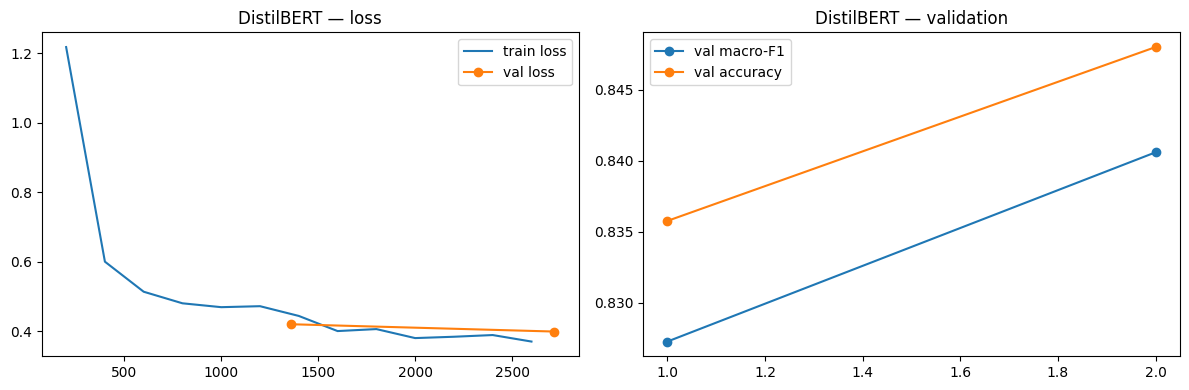

In [18]:
log = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tr = log[log['loss'].notna()] if 'loss' in log else log.iloc[0:0]
ev = log[log['eval_loss'].notna()] if 'eval_loss' in log else log.iloc[0:0]
ax[0].plot(tr['step'], tr['loss'], label='train loss'); ax[0].plot(ev['step'], ev['eval_loss'], 'o-', label='val loss'); ax[0].legend(); ax[0].set_title('DistilBERT — loss')
ax[1].plot(ev['epoch'], ev['eval_macro_f1'], 'o-', label='val macro-F1'); ax[1].plot(ev['epoch'], ev['eval_accuracy'], 'o-', label='val accuracy'); ax[1].legend(); ax[1].set_title('DistilBERT — validation')
plt.tight_layout(); plt.show()

## 5.6 Evaluate on the test set (same metrics as the other models)

===== DistilBERT =====
Accuracy 0.8479 | Macro-Precision 0.8217 | Macro-Recall 0.8591 | Macro-F1 0.8382

                     precision    recall  f1-score   support

        credit_card      0.747     0.841     0.791      2245
   credit_reporting      0.938     0.825     0.878      8414
    debt_collection      0.752     0.848     0.797      3145
mortgages_and_loans      0.825     0.890     0.856      2804
     retail_banking      0.846     0.891     0.868      2017

           accuracy                          0.848     18625
          macro avg      0.822     0.859     0.838     18625
       weighted avg      0.857     0.848     0.850     18625



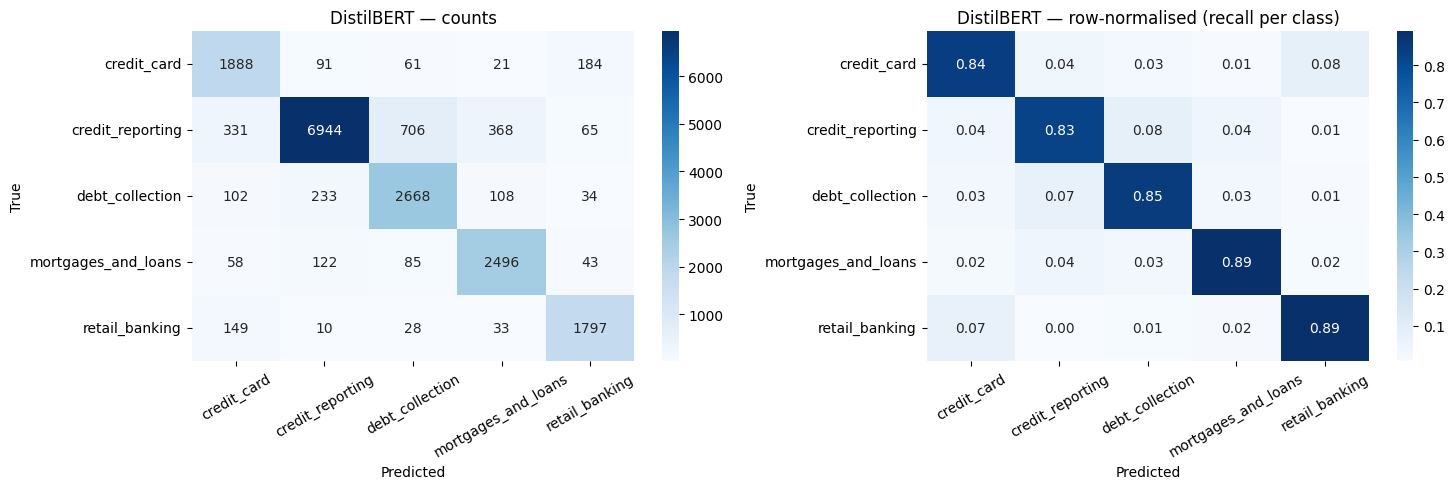

In [19]:
def evaluate_model(name, y_true, y_pred, plot=True):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    print(f'===== {name} =====')
    print(f'Accuracy {acc:.4f} | Macro-Precision {p:.4f} | Macro-Recall {r:.4f} | Macro-F1 {f1:.4f}\n')
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    if plot:
        cmn = cm / cm.sum(axis=1, keepdims=True)
        fig, ax = plt.subplots(1, 2, figsize=(15, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax[0]); ax[0].set_title(f'{name} — counts')
        sns.heatmap(cmn, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax[1]); ax[1].set_title(f'{name} — row-normalised (recall per class)')
        for a in ax: a.set_xlabel('Predicted'); a.set_ylabel('True'); a.tick_params(axis='x', rotation=30)
        plt.tight_layout(); plt.show()
    res = {'model': name, 'accuracy': acc, 'macro_precision': p, 'macro_recall': r, 'macro_f1': f1, 'confusion_matrix': cm.tolist()}
    return res

pred = trainer.predict(ds_test)
logits = pred.predictions
probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
y_test = test_df['label'].values

res_bert = evaluate_model('DistilBERT', y_test, probs.argmax(1))
res_bert['train_minutes'] = train_minutes
res_bert['params'] = int(model.num_parameters())
json.dump(res_bert, open('results/DistilBERT.json', 'w'))
np.save('results/DistilBERT_test_probs.npy', probs)

## 5.7 Save the model for Gradio (Step 7)

In [20]:
trainer.save_model('models/distilbert_complaints')
tokenizer.save_pretrained('models/distilbert_complaints')
print(os.listdir('models/distilbert_complaints'))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['tokenizer.json', 'config.json', 'tokenizer_config.json', 'model.safetensors', 'training_args.bin']


## 5.8 Comparison of everything so far
Pulls the JSON results saved by Steps 3 and 4 (if you added them as inputs).

       model  accuracy  macro_precision  macro_recall  macro_F1  train_min     params
TFIDF_LogReg    0.8628           0.8401        0.8629    0.8507        NaN        NaN
   SimpleRNN    0.8154           0.7843        0.8101    0.7962     2.7883        NaN
        LSTM    0.8306           0.8080        0.8321    0.8172     1.1826  2609733.0
         GRU    0.8453           0.8237        0.8485    0.8342     0.8891  2597573.0
  DistilBERT    0.8479           0.8217        0.8591    0.8382    38.6945 66957317.0


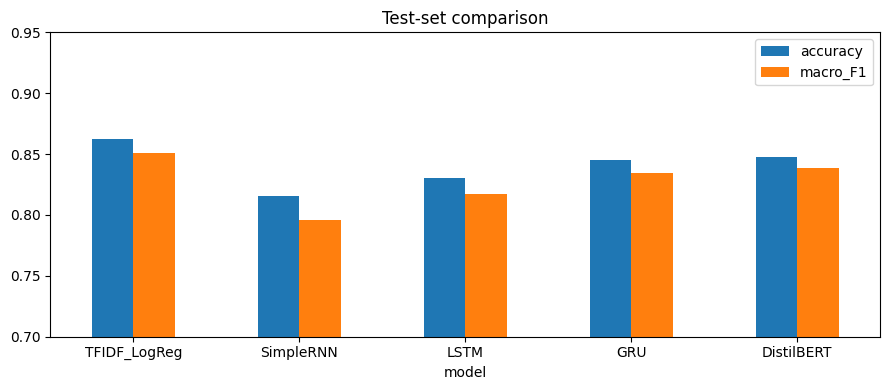

In [21]:
rows = []
for n in ['TFIDF_LogReg', 'SimpleRNN', 'LSTM', 'GRU']:
    p = find(f'results/{n}.json', required=False)
    if p: rows.append(json.load(open(p)))
rows.append(res_bert)

comp = pd.DataFrame([{'model': r['model'], 'accuracy': r['accuracy'], 'macro_precision': r['macro_precision'],
                      'macro_recall': r['macro_recall'], 'macro_F1': r['macro_f1'],
                      'train_min': r.get('train_minutes'), 'params': r.get('params')} for r in rows]).round(4)
print(comp.to_string(index=False))

ax = comp.set_index('model')[['accuracy', 'macro_F1']].plot.bar(figsize=(9, 4), ylim=(0.7, 0.95), rot=0)
ax.set_title('Test-set comparison'); plt.tight_layout(); plt.show()